In [1]:
######## snakemake preamble start (automatically inserted, do not edit) ########
import sys;sys.path.extend(['/Users/jbwang/miniconda3/envs/snakemake/lib/python3.13/site-packages', '/Users/jbwang/Documents/Flamholz Lab/repos/diagram_dynamic_metabolism_v2/workflow', '/Users/jbwang/miniconda3/envs/snakemake/bin', '/Users/jbwang/miniconda3/envs/snakemake/lib/python3.13', '/Users/jbwang/miniconda3/envs/snakemake/lib/python3.13/lib-dynload', '/Users/jbwang/miniconda3/envs/snakemake/lib/python3.13/site-packages', '/Users/jbwang/Library/Caches/snakemake/snakemake/source-cache/runtime-cache/tmp3u7frwst/file/Users/jbwang/Documents/Flamholz Lab/repos/diagram_dynamic_metabolism_v2/workflow/notebooks', '/Users/jbwang/Documents/Flamholz Lab/repos/diagram_dynamic_metabolism_v2/workflow/notebooks']);import pickle;from snakemake import script;script.snakemake = pickle.loads(b'\x80\x04\x95\xf7\x03\x00\x00\x00\x00\x00\x00\x8c\x10snakemake.script\x94\x8c\tSnakemake\x94\x93\x94)\x81\x94}\x94(\x8c\x05input\x94\x8c\x0csnakemake.io\x94\x8c\nInputFiles\x94\x93\x94)\x81\x94\x8c"resources/data/six_state_trees.pkl\x94a}\x94(\x8c\x06_names\x94}\x94\x8c\x12_allowed_overrides\x94]\x94(\x8c\x05index\x94\x8c\x04sort\x94eh\x10h\x06\x8c\x0eAttributeGuard\x94\x93\x94)\x81\x94}\x94\x8c\x04name\x94h\x10sbh\x11h\x13)\x81\x94}\x94h\x16h\x11sbub\x8c\x06output\x94h\x06\x8c\x0bOutputFiles\x94\x93\x94)\x81\x94\x8c&resources/subfigures/fig_2c_fluxes.svg\x94a}\x94(h\x0c}\x94h\x0e]\x94(h\x10h\x11eh\x10h\x13)\x81\x94}\x94h\x16h\x10sbh\x11h\x13)\x81\x94}\x94h\x16h\x11sbub\x8c\r_params_store\x94h\x06\x8c\x06Params\x94\x93\x94)\x81\x94}\x94(h\x0c}\x94h\x0e]\x94(h\x10h\x11eh\x10h\x13)\x81\x94}\x94h\x16h\x10sbh\x11h\x13)\x81\x94}\x94h\x16h\x11sbub\x8c\r_params_types\x94}\x94\x8c\twildcards\x94h\x06\x8c\tWildcards\x94\x93\x94)\x81\x94}\x94(h\x0c}\x94h\x0e]\x94(h\x10h\x11eh\x10h\x13)\x81\x94}\x94h\x16h\x10sbh\x11h\x13)\x81\x94}\x94h\x16h\x11sbub\x8c\x07threads\x94K\x01\x8c\tresources\x94h\x06\x8c\tResources\x94\x93\x94)\x81\x94(K\x01K\x01\x8c0/var/folders/98/m6nhh0gx4nsgd2v7r1tl07cc0000gn/T\x94e}\x94(h\x0c}\x94(\x8c\x06_cores\x94K\x00N\x86\x94\x8c\x06_nodes\x94K\x01N\x86\x94\x8c\x06tmpdir\x94K\x02N\x86\x94uh\x0e]\x94(h\x10h\x11eh\x10h\x13)\x81\x94}\x94h\x16h\x10sbh\x11h\x13)\x81\x94}\x94h\x16h\x11sbhEK\x01hGK\x01hIhBub\x8c\x03log\x94h\x06\x8c\x03Log\x94\x93\x94)\x81\x94\x8c\x1blogs/run_fig2c_fluxes.ipynb\x94a}\x94(h\x0c}\x94\x8c\x08notebook\x94K\x00N\x86\x94sh\x0e]\x94(h\x10h\x11eh\x10h\x13)\x81\x94}\x94h\x16h\x10sbh\x11h\x13)\x81\x94}\x94h\x16h\x11sbhWhTub\x8c\x06config\x94}\x94\x8c\x04rule\x94\x8c\rfig_2c_fluxes\x94\x8c\x0fbench_iteration\x94N\x8c\tscriptdir\x94\x8c[/Users/jbwang/Documents/Flamholz Lab/repos/diagram_dynamic_metabolism_v2/workflow/notebooks\x94ub.');del script;from snakemake.logging import logger;from snakemake.script import snakemake;import os; os.chdir(r'/Users/jbwang/Documents/Flamholz Lab/repos/diagram_dynamic_metabolism_v2/workflow');
######## snakemake preamble end #########


In [2]:
# start coding here
import mpmath
import numpy as np
import bokeh.layouts
import bokeh.models
import bokeh.plotting

from IPython.display import display
from jupyter_bokeh.widgets import BokehModel
from bokeh.io import output_notebook, export_svg, export_png
from bokeh.plotting import figure
from ipywidgets import interact

from bokeh.io import output_file, show, export_svgs
from bokeh.layouts import row
from bokeh.models import Ellipse, GraphRenderer, StaticLayoutProvider, Circle
from bokeh.palettes import Spectral6, Reds3, brewer
from bokeh.plotting import figure
from IPython.display import display
from bokeh.models import (Arrow, Label, NormalHead, OpenHead,
                          Plot, Range1d, TeeHead, VeeHead)
from bokeh.models import MathML
from lib.six_state_model import dynamic_steady_state_diagram
import pickle as pkl
output_notebook()


Loading BokehJS ...

In [3]:
spanTreesGraph = pkl.load(open(snakemake.input[0], 'rb')) 

def find_J_tot_list(epsilon_list, dG_1, dG_2, alpha_21, alpha_32, gamma, spanTreesGraph=spanTreesGraph):
    J_tot_list = []
    alpha_14 = 1e11
    alpha_41 = 1e11 
    for epsilon in epsilon_list:
        epsilon_1 = epsilon
        epsilon_2 = epsilon
        J_1, J_2, J_3, J_4, J_5, J_6, J_7, J_8, J_9, J_10, J_11, J_f1, J_f2, J_f3 = dynamic_steady_state_diagram(epsilon_1, epsilon_2, alpha_21, alpha_32, gamma, gamma, alpha_14, alpha_41, dG_1=dG_1, dG_2=dG_2, k_bT=1, spanTreesGraph=spanTreesGraph)
        J_1 = float(J_1)
        J_2 = float(J_2)
        J_3 = float(J_3)
        J_4 = float(J_4)
        J_5 = float(J_5)
        J_6 = float(J_6)
        J_7 = float(J_7)
        J_8 = float(J_8)
        J_9 = float(J_9)
        J_10 = float(J_10)
        J_11 = float(J_11)
        J_f1 = float(J_f1)
        J_f2 = float(J_f2)
        J_f3 = float(J_f3)
    
        J_tot = np.abs(J_4) + np.abs(J_5) + np.abs(J_6) + np.abs(J_7) + np.abs(J_8) + np.abs(J_9) + np.abs(J_10) + np.abs(J_11)
        J_tot_list.append(J_tot)
    return J_tot_list

In [4]:
from bokeh.models import LinearColorMapper, ColorBar, BasicTicker
from bokeh.palettes import Spectral6
oscMidpoint = 0
k_bT = 1
dG_1 = 2
dG_2 = 2


alpha_21 = 1
alpha_32 = 1

alpha_54 = 1 
alpha_65 = 1 
gamma = 20000
amplitude = 2
alpha_14 = 25
alpha_41 = 25
## S3 definition
cats = [ r'steady-state', r'dynamic steady-state', r'futile cycles']
fluxes = [r'nonenhanced', r'enhanced',  r'impeded', r'futile', r'optimum']
s3 = figure(title="Cycle fluxes", x_range=cats, y_range=(0,5), toolbar_location=None, tools="hover", tooltips="$name: @$name", width=288, height=208)
data = {'cats': cats,
        'optimum': [None,0, None],
        'nonenhanced': [0,0, None],
        'enhanced': [0,0, None],
        'impeded': [0,0, None],
        'futile': [None, None, 0],
        }
source_2 = bokeh.models.ColumnDataSource(data=data)
s3.vbar_stack(fluxes, x='cats', width=0.9, source=source_2, color=Spectral6[:-1], line_color=None, legend_label=fluxes)
s3.legend.location = "top_left"
s3.legend.orientation = "horizontal"
s3.yaxis.axis_label = "Flux [$$s^{-1}$$]"
s3.xaxis.major_label_text_font_size = '6pt'
s3.legend.label_text_font_size = '6pt'
s3.legend.items[3].visible = False
s3.legend.items[4].visible = False

# S3 update
#s1 update
epsilon_list = np.linspace(-5,5,50)
J_tot_list = find_J_tot_list(epsilon_list, dG_1, dG_2, alpha_21, alpha_32, gamma)
idx_eps = np.argmin(np.abs(J_tot_list - np.max(J_tot_list)))
oscMidpoint = epsilon_list[idx_eps] / 2

epsilon_1 = float(oscMidpoint + amplitude/2)
epsilon_2 = float(oscMidpoint - amplitude/2)
J_1, J_2, J_3, J_4, J_5, J_6, J_7, J_8, J_9, J_10, J_11, Jf1, Jf2, Jf3 = dynamic_steady_state_diagram(epsilon_1, epsilon_2, alpha_21, alpha_32, \
                                                                gamma, gamma, alpha_14, alpha_41, dG_1=dG_1, dG_2=dG_2, k_bT=1, spanTreesGraph=spanTreesGraph)
J_1 = float(J_1)
J_2 = float(J_2)
J_3 = float(J_3)
J_4 = float(J_4)
J_5 = float(J_5)
J_6 = float(J_6)
J_7 = float(J_7)
J_8 = float(J_8)
J_9 = float(J_9)
J_10 = float(J_10)
J_11 = float(J_11)
Jf1 = float(Jf1)
Jf2 = float(Jf2)
Jf3 = float(Jf3)

J_enhanced = np.abs(J_10) + np.abs(J_8)
J_nonenhanced = np.abs(J_4) + np.abs(J_5) + np.abs(J_6) + np.abs(J_7)
J_impeded = np.abs(J_9) + np.abs(J_11)
J_futile = np.abs(J_1) + np.abs(J_2) + np.abs(J_3) + np.abs(Jf1) + np.abs(Jf2) + np.abs(Jf3)
J_steady_state_optimum = np.max(J_tot_list)

source_2.data = {'cats': cats,
    'optimum': [J_steady_state_optimum, None, None],
    'enhanced': [None, J_enhanced, None],
    'nonenhanced': [None, J_nonenhanced, None],
    'impeded': [None, J_impeded, None],
    'futile': [None,None, J_futile],
    }

    

s3.output_backend = "svg"
plot = row(s3, )
# plot = row(s1, s2, s3)
# interact(update, gamma=(0, 20, 0.1,), dG_1 = (-5,5,0.1), dG_2 = (-5,5,0.1), amplitude=(0,5,0.1), alpha_41=(1e-11,100,1), alpha_14=(1e-11,100,1))

display(BokehModel(plot))

export_svg(plot, filename=snakemake.output[0])

interactive_python_plots = True
output_notebook()

BokehModel(render_bundle={'docs_json': {'4a7c5ffd-e170-4f5a-b589-cefd621f1ee6': {'version': '3.6.2', 'title': …

Loading BokehJS ...

In [5]:
epsilon_list = np.linspace(-5,5,50)
J_tot_list = find_J_tot_list(epsilon_list, dG_1, dG_2, alpha_21, alpha_32, gamma)
idx_eps = np.argmin(np.abs(J_tot_list - np.max(J_tot_list)))
oscMidpoint = epsilon_list[idx_eps] / 2
k_bT = 1
dG_1 = 2
dG_2 = 2


alpha_21 = 1
alpha_32 = 1

alpha_54 = 1 
alpha_65 = 1 
gamma = 20000
amplitude = 2
alpha_14 = 25
alpha_41 = 25
cats = [ r'steady-state', r'dynamic steady-state', r'futile cycles']
fluxes = [r'nonenhanced', r'enhanced',  r'impeded', r'futile', r'optimum']
epsilon_1 = float(oscMidpoint + amplitude/2)
epsilon_2 = float(oscMidpoint - amplitude/2)
J_1, J_2, J_3, J_4, J_5, J_6, J_7, J_8, J_9, J_10, J_11, Jf1, Jf2, Jf3 = dynamic_steady_state_diagram(epsilon_1, epsilon_2, alpha_21, alpha_32, \
                                                                gamma, gamma, alpha_14, alpha_41, dG_1=dG_1, dG_2=dG_2, k_bT=1, spanTreesGraph=spanTreesGraph)
J_1 = float(J_1)
J_2 = float(J_2)
J_3 = float(J_3)
J_4 = float(J_4)
J_5 = float(J_5)
J_6 = float(J_6)
J_7 = float(J_7)
J_8 = float(J_8)
J_9 = float(J_9)
J_10 = float(J_10)
J_11 = float(J_11)
Jf1 = float(Jf1)
Jf2 = float(Jf2)
Jf3 = float(Jf3)

J_enhanced = np.abs(J_10) + np.abs(J_8)
J_nonenhanced = np.abs(J_4) + np.abs(J_5) + np.abs(J_6) + np.abs(J_7)
J_impeded = np.abs(J_9) + np.abs(J_11)
J_futile = np.abs(J_1) + np.abs(J_2) + np.abs(J_3) + np.abs(Jf1) + np.abs(Jf2) + np.abs(Jf3)
J_steady_state_optimum = np.max(J_tot_list)

data = {
    None: [J_steady_state_optimum, 0, 0],
    'enhanced': [0, J_enhanced, 0],
    'unperturbed': [0, J_nonenhanced, 0],
    'impeded': [0, J_impeded, 0],
    '': [0,0, J_futile],
    }


findfont: Font family 'Lucida Sans' not found.


findfont: Font family 'Lucida Sans' not found.


findfont: Font family 'Lucida Sans' not found.


findfont: Font family 'Lucida Sans' not found.


findfont: Font family 'Lucida Sans' not found.


findfont: Font family 'Lucida Sans' not found.


... (158 outputs left out)

findfont: Font family 'Lucida Sans' not found.


findfont: Font family 'Lucida Sans' not found.


findfont: Font family 'Lucida Sans' not found.


findfont: Font family 'Lucida Sans' not found.


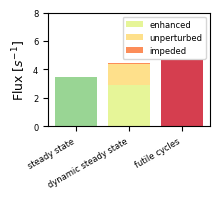

In [6]:
from bokeh.palettes import Spectral6
categories = (
    "steady state",
    "dynamic steady state",
    "futile cycles",
)


width = 0.8

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(2.3,2.1))
bottom = np.zeros(3)
i=0
for category, data_row in data.items():
    p = ax.bar(categories, data_row, width, label=category, bottom=bottom, color=Spectral6[i+1])
    i+=1
    bottom += data_row

plt.xticks(rotation=30, ha='right', font='Lucida Sans', fontsize=6)
plt.yticks(font='Lucida Sans', fontsize=6)
plt.ylim(0,8)
ax.set_ylabel(r"Flux [$s^{-1}$]", fontdict={'name': 'Lucida Sans', 'size': 9})
l = ax.legend(loc="upper right", fontsize=6)

plt.setp(l.texts, name='Lucida Sans')
plt.tight_layout()
plt.savefig(snakemake.output[0], format='svg')

